I.) Load data and data cleaning

1.) Import libraries


In [47]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import GEOparse


2.) Load PFC mRNA data into a dataframe

In [48]:
pfc_mrna_file = "data/GSE22521_series_matrix.txt"


pfc_mrna = pd.read_csv(
    pfc_mrna_file,
    sep="\t",
    comment="!",
    index_col=0
)

3.) Have a look at the data

In [49]:
print(pfc_mrna.shape)

print(pfc_mrna.head())

(13042, 68)
         GSM559183  GSM559184  GSM559185  GSM559186  GSM559187  GSM559188  \
ID_REF                                                                      
7896822   3.924486   4.209343   2.558671   4.434798   3.664290   3.628356   
7897034   4.363519   4.345616   3.768352   2.571772   4.083087   4.760077   
7897044   4.601810   5.095022   4.617025   4.396065   4.889153   4.575935   
7897068   3.806804   3.950793   3.108032   4.385707   3.521073   3.809370   
7897078   5.362968   5.503288   5.244282   5.053874   5.328000   5.461167   

         GSM559189  GSM559190  GSM559191  GSM559192  ...  GSM559241  \
ID_REF                                               ...              
7896822   2.824752   3.433710   2.164794   2.957314  ...   2.536889   
7897034   4.256415   4.144009   3.522481   4.214889  ...   3.627683   
7897044   4.763925   4.740030   4.369615   4.968942  ...   4.439761   
7897068   3.074784   3.629333   2.836160   3.097626  ...   3.419544   
7897078   5.422790   5

In [50]:
round(pfc_mrna.describe(),2)

,GSM559183,GSM559184,GSM559185,GSM559186,GSM559187,GSM559188,GSM559189,GSM559190,GSM559191,GSM559192,...,GSM559241,GSM559242,GSM559243,GSM559244,GSM559245,GSM559246,GSM559247,GSM559248,GSM559249,GSM559250
count,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,...,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00,13042.00
mean,3.89,3.87,3.82,3.87,3.83,3.89,3.84,3.87,3.82,3.82,...,3.87,3.83,3.87,3.79,3.84,3.81,3.85,3.85,3.82,3.82
std,1.68,1.68,1.73,1.64,1.74,1.67,1.71,1.70,1.70,1.74,...,1.70,1.69,1.64,1.69,1.69,1.70,1.72,1.69,1.71,1.71
min,-0.96,-1.40,-2.05,-1.26,-1.05,-1.18,-2.40,-1.88,-2.12,-2.72,...,-1.19,-2.01,-2.12,-1.58,-1.59,-2.22,-1.76,-2.22,-1.91,-2.18
25%,2.73,2.70,2.53,2.74,2.57,2.73,2.58,2.67,2.54,2.52,...,2.61,2.59,2.71,2.52,2.62,2.52,2.60,2.61,2.56,2.55
50%,3.89,3.86,3.80,3.89,3.83,3.90,3.84,3.88,3.78,3.80,...,3.87,3.82,3.86,3.78,3.83,3.77,3.84,3.80,3.78,3.79
75%,5.06,5.04,5.08,5.00,5.06,5.06,5.08,5.07,5.04,5.07,...,5.08,5.02,5.00,5.02,5.04,5.05,5.08,5.06,5.04,5.06
max,9.22,10.31,10.04,10.25,9.66,9.57,9.58,9.52,9.68,9.49,...,9.91,10.21,10.25,9.49,10.39,9.67,9.78,9.60,9.54,10.09


4.) The info Table S1 states 61 individuals, but the array shows 68. 4 were tested twice. That means there is still a discrepancy. We have to fnd out which onese were taken out. We will use GEOparse on the info file "_family.soft"

In [51]:
gse = GEOparse.get_GEO(
    filepath="data/GSE22521_family.soft",
    include_data=True,
    silent=False
) 

12-Oct-2026 20:47:44 INFO GEOparse - Parsing data/GSE22521_family.soft: 
12-Oct-2026 20:47:44 DEBUG GEOparse - DATABASE: GeoMiame
12-Oct-2026 20:47:44 DEBUG GEOparse - SERIES: GSE22521
12-Oct-2026 20:47:44 DEBUG GEOparse - PLATFORM: GPL6244
12-Oct-2026 20:47:50 DEBUG GEOparse - SAMPLE: GSM559183
12-Oct-2026 20:47:50 DEBUG GEOparse - SAMPLE: GSM559184
12-Oct-2026 20:47:50 DEBUG GEOparse - SAMPLE: GSM559185
12-Oct-2026 20:47:50 DEBUG GEOparse - SAMPLE: GSM559186
12-Oct-2026 20:47:50 DEBUG GEOparse - SAMPLE: GSM559187
12-Oct-2026 20:47:50 DEBUG GEOparse - SAMPLE: GSM559188
12-Oct-2026 20:47:50 DEBUG GEOparse - SAMPLE: GSM559189
12-Oct-2026 20:47:50 DEBUG GEOparse - SAMPLE: GSM559190
12-Oct-2026 20:47:50 DEBUG GEOparse - SAMPLE: GSM559191
12-Oct-2026 20:47:50 DEBUG GEOparse - SAMPLE: GSM559192
12-Oct-2026 20:47:50 DEBUG GEOparse - SAMPLE: GSM559193
12-Oct-2026 20:47:50 DEBUG GEOparse - SAMPLE: GSM559194
12-Oct-2026 20:47:50 DEBUG GEOparse - SAMPLE: GSM559195
12-Oct-2026 20:47:51 DEBUG GEOp

5.) GEOparse creates a Python object containing the study information. gse.gsms is a a Python dictionary containing the sample objects. We check how many there are.

In [52]:
print(type(gse))
print(gse.name)
print(len(gse.gsms))

<class 'GEOparse.GEOTypes.GSE'>
GSE22521
68


6.) We check the metadata for one individual

In [53]:
test_ind = gse.gsms["GSM559248"]

print( f"Name : {test_ind.name}")
print( f"Metadata : {test_ind.metadata}")
print( f"Table : {test_ind.table}")
print( f"Columns : {test_ind.columns}")



Name : GSM559248
Metadata : {'title': ['Chimpanzee - superior frontal gyrus - 4500 days old'], 'geo_accession': ['GSM559248'], 'status': ['Public on Dec 09 2011'], 'submission_date': ['Jun 23 2010'], 'last_update_date': ['Dec 09 2011'], 'type': ['RNA'], 'channel_count': ['1'], 'source_name_ch1': ['Dissected Chimpanzee post-mortem superior frontal gyrus'], 'organism_ch1': ['Pan troglodytes'], 'taxid_ch1': ['9598'], 'characteristics_ch1': ['age: 4500 days', 'gender: m', 'tissue: superior frontal gyrus of the brain', 'post-mortem interval (hours): -', 'rna integrity number (rin): 5.9', 'batch: 1'], 'biomaterial_provider_ch1': ['BPRC, Rijswijk, Netherlands'], 'treatment_protocol_ch1': ['All human postmortem brain tissue samples were obtained from the NICHD Brain and Tissue Bank for Developmental Disorders (NICHDBB)(Baltimore, MD, USA). All subjects were defined as normal controls by forensic pathologists at the NICHDBB. No subjects with prolonged agonal state were used. Chimpanzee samples 

7.) We check the metadata to explain the discrepancy.

In [54]:
records = []

for gsm_id, gsm in gse.gsms.items():
    records.append({
        "GSM": gsm_id,
        "Title": gsm.metadata.get("title", [None])[0],
        "Source": gsm.metadata.get("source_name_ch1", [None])[0],
        "Characteristics": gsm.metadata.get("characteristics_ch1", []),
        "Description": gsm.metadata.get("description", [])
    })

sample_info = pd.DataFrame(records)

display(sample_info.head(10))

,GSM,Title,Source,Characteristics,Description
0,GSM559183,Human - superior frontal gyrus - 14309 days old,Dissected Human post-mortem superior frontal g...,"[age: 14309 days, gender: m, tissue: superior ...",[The dataset contains two prenatal individuals...
1,GSM559184,Human - superior frontal gyrus - 1630 days old,Dissected Human post-mortem superior frontal g...,"[age: 1630 days, gender: f, tissue: superior f...",[The dataset contains two prenatal individuals...
2,GSM559185,Human - superior frontal gyrus - 19457 days old,Dissected Human post-mortem superior frontal g...,"[age: 19457 days, gender: m, tissue: superior ...",[The dataset contains two prenatal individuals...
3,GSM559186,Human - superior frontal gyrus - 19 days old,Dissected Human post-mortem superior frontal g...,"[age: 19 days, gender: f, tissue: superior fro...",[The dataset contains two prenatal individuals...
4,GSM559187,Human - superior frontal gyrus - 204 days old,Dissected Human post-mortem superior frontal g...,"[age: 204 days, gender: m, tissue: superior fr...",[The dataset contains two prenatal individuals...
5,GSM559188,Human - superior frontal gyrus - 21204 days old,Dissected Human post-mortem superior frontal g...,"[age: 21204 days, gender: m, tissue: superior ...",[The dataset contains two prenatal individuals...
6,GSM559189,Human - superior frontal gyrus - 24090 days old,Dissected Human post-mortem superior frontal g...,"[age: 24090 days, gender: m, tissue: superior ...",[The dataset contains two prenatal individuals...
7,GSM559190,Human - superior frontal gyrus - 28692 days old,Dissected Human post-mortem superior frontal g...,"[age: 28692 days, gender: f, tissue: superior ...",[The dataset contains two prenatal individuals...
8,GSM559191,Human - superior frontal gyrus - 29200 days old,Dissected Human post-mortem superior frontal g...,"[age: 29200 days, gender: m, tissue: superior ...",[The dataset contains two prenatal individuals...
9,GSM559192,Human - superior frontal gyrus - 2922 days old,Dissected Human post-mortem superior frontal g...,"[age: 2922 days, gender: m, tissue: superior f...",[The dataset contains two prenatal individuals...


In [55]:
print(sample_info[["GSM", "Title"]].to_string(index=False))

sample_info.to_csv("data/pfc_mrna_sample_info.csv", index=False)

      GSM                                                              Title
GSM559183                    Human - superior frontal gyrus - 14309 days old
GSM559184                     Human - superior frontal gyrus - 1630 days old
GSM559185                    Human - superior frontal gyrus - 19457 days old
GSM559186                       Human - superior frontal gyrus - 19 days old
GSM559187                      Human - superior frontal gyrus - 204 days old
GSM559188                    Human - superior frontal gyrus - 21204 days old
GSM559189                    Human - superior frontal gyrus - 24090 days old
GSM559190                    Human - superior frontal gyrus - 28692 days old
GSM559191                    Human - superior frontal gyrus - 29200 days old
GSM559192                     Human - superior frontal gyrus - 2922 days old
GSM559193               Human - superior frontal gyrus - 2 days old (batch1)
GSM559194               Human - superior frontal gyrus - 2 days old (batch2)

7.i) Add species and age information to sample_info

In [56]:
sample_info["Species"] = (
    sample_info["Title"]
    .str.extract(r"^(Human|Chimpanzee|Rhesus macaque)", expand=False)
)

sample_info["Age_days"] = pd.to_numeric(
    sample_info["Title"]
    .str.extract(r"(\d+)\s+days?\s+old", expand=False),
    errors="coerce"
)

sample_info["Log2_Age"] = np.log2(sample_info["Age_days"] + 1)

print(sample_info.head())

sample_info.to_csv("data/pfc_mrna_sample_info.csv", index=False)

         GSM                                            Title  \
0  GSM559183  Human - superior frontal gyrus - 14309 days old   
1  GSM559184   Human - superior frontal gyrus - 1630 days old   
2  GSM559185  Human - superior frontal gyrus - 19457 days old   
3  GSM559186     Human - superior frontal gyrus - 19 days old   
4  GSM559187    Human - superior frontal gyrus - 204 days old   

                                              Source  \
0  Dissected Human post-mortem superior frontal g...   
1  Dissected Human post-mortem superior frontal g...   
2  Dissected Human post-mortem superior frontal g...   
3  Dissected Human post-mortem superior frontal g...   
4  Dissected Human post-mortem superior frontal g...   

                                     Characteristics  \
0  [age: 14309 days, gender: m, tissue: superior ...   
1  [age: 1630 days, gender: f, tissue: superior f...   
2  [age: 19457 days, gender: m, tissue: superior ...   
3  [age: 19 days, gender: f, tissue: superior fr

8.) We take the 5 individuals with duplicate measurements and check if they are correlated

In [57]:
duplicate_pairs = pd.DataFrame({
    "GSM1": [
        "GSM559193", "GSM559198", "GSM559208", "GSM559215", "GSM559223"
    ],
    "GSM2": [
        "GSM559194", "GSM559199", "GSM559209", "GSM559216", "GSM559224"
    ]
})


for _, row in duplicate_pairs.iterrows():
    gsm1 = row["GSM1"]
    gsm2 = row["GSM2"]

    correlation = pfc_mrna[gsm1].corr(pfc_mrna[gsm2])

    print(gsm1, gsm2, "Correlation:", round(correlation, 4))

GSM559193 GSM559194 Correlation: 0.9415
GSM559198 GSM559199 Correlation: 0.9454
GSM559208 GSM559209 Correlation: 0.9821


GSM559215 GSM559216 Correlation: 0.9721
GSM559223 GSM559224 Correlation: 0.9764


8.) Another individual was not in Table S1, we identified it using an LLM. It is GSM559211 who is 1487 days or 4 years and 17 days old. 
    We make an exclusion list and a reduced table and check for missing values and duplicates

In [58]:
exclusion_list = ["GSM559194", "GSM559199", "GSM559209", "GSM559216", "GSM559224", "GSM559211"]

In [59]:
pfc_mrna_clean = pfc_mrna.drop(columns=exclusion_list)

pfc_mrna_clean.columns

print(pfc_mrna_clean.isna().sum().sum())

print("Duplicate feature IDs:",
      pfc_mrna_clean.index.duplicated().sum())

print("Duplicate GSM IDs:",
      pfc_mrna_clean.columns.duplicated().sum())


0
Duplicate feature IDs: 0
Duplicate GSM IDs: 0


9.) We make a new metadata table and look at the age distribution

In [60]:
sample_info_clean = sample_info[
    ~sample_info["GSM"].isin(exclusion_list)
].copy()

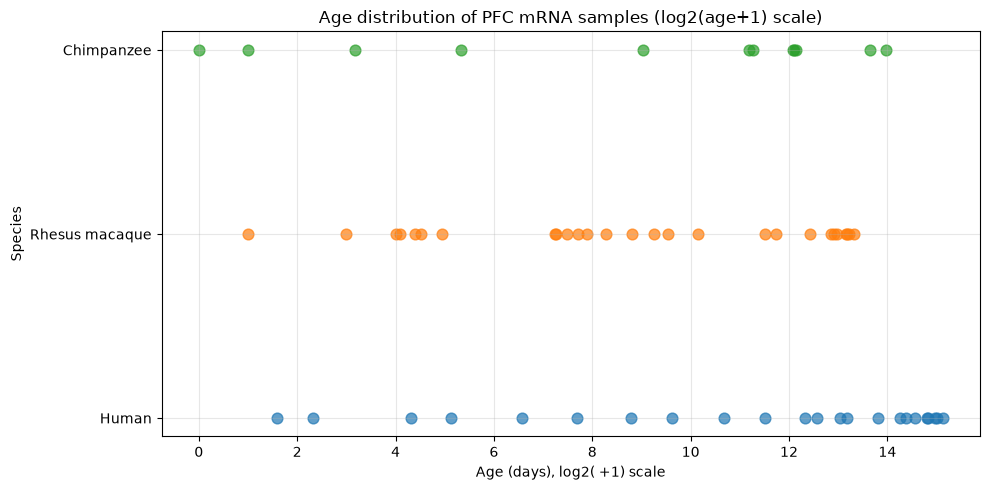

In [61]:
plt.figure(figsize=(10, 5))

for species in sample_info_clean["Species"].unique():
    
    subset = sample_info_clean[
        sample_info_clean["Species"] == species
    ]
    
    plt.scatter(
        subset["Log2_Age"],
        [species] * len(subset),
        label=species,
        s=60,
        alpha=0.7
    )

plt.xlabel("Age (days), log2( +1) scale")
plt.ylabel("Species")
plt.title("Age distribution of PFC mRNA samples (log2(age+1) scale)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

10.) Trying to find an outlier macaque. We extract the species data and correlate all individuals

In [62]:
species_ids = {}
corr = {}
median_corr = {}

for i in sample_info_clean["Species"].unique():

    info = sample_info_clean[
        sample_info_clean["Species"] == i
    ].copy()

    species_ids[i] = info["GSM"].tolist()

    spec_mrna = pfc_mrna_clean[species_ids[i]]

    corr[i] = spec_mrna.corr()

    median_corr[i] = corr[i].mask(
        np.eye(len(corr[i]), dtype=bool)
    ).median()

    print(f"\nSpecies: {i}")
    display(median_corr[i].sort_values().head(10))



Species: Human


GSM559193    0.845729
GSM559186    0.877110
GSM559201    0.906572
GSM559191    0.920674
GSM559197    0.921499
GSM559200    0.927352
GSM559207    0.928219
GSM559198    0.928756
GSM559185    0.933086
GSM559202    0.933726
dtype: float64


Species: Rhesus macaque


GSM559225    0.885962
GSM559229    0.922054
GSM559214    0.925741
GSM559232    0.927417
GSM559236    0.929807
GSM559227    0.930108
GSM559226    0.931029
GSM559238    0.931973
GSM559233    0.933965
GSM559235    0.934188
dtype: float64


Species: Chimpanzee


GSM559245    0.917097
GSM559250    0.919824
GSM559242    0.922950
GSM559239    0.928499
GSM559241    0.935504
GSM559243    0.946899
GSM559244    0.947299
GSM559246    0.947619
GSM559240    0.949751
GSM559248    0.953120
dtype: float64

Check correlation between the two human outliers GSM559193 (2 days old) and GSM559186 (19 days old) and GSM559201 (4 days old) 

In [63]:
sample1 = "GSM559193"
sample2 = "GSM559186"

r = pfc_mrna[sample1].corr(pfc_mrna[sample2])

print("Pearson correlation:", r)

Pearson correlation: 0.8635713628008224


In [64]:
sample1 = "GSM559193"
sample2 = "GSM559201"

r = pfc_mrna[sample1].corr(pfc_mrna[sample2])

print("Pearson correlation:", r)

Pearson correlation: 0.9466211083109638


In [65]:
sample1 = "GSM559186"
sample2 = "GSM559201"

r = pfc_mrna[sample1].corr(pfc_mrna[sample2])

print("Pearson correlation:", r)

Pearson correlation: 0.8944865317671229


In [88]:
human_samples = sample_info.loc[
    sample_info["Species"] == "Human",
    "GSM"
]

corr_19days = (
    pfc_mrna[human_samples]
    .corr()["GSM559186"]
    .drop("GSM559186")
)

# Combine correlations with ages
corr_info = sample_info.set_index("GSM").loc[corr_19days.index, [
    "Age_days", "Log2_Age"
]].copy()

corr_info["Correlation"] = corr_19days

# Sort by age
corr_info = corr_info.sort_values("Correlation")

corr_info.tail()

,Age_days,Log2_Age,Correlation
GSM559194,2,1.584963,0.901508
GSM559200,443,8.794416,0.902535
GSM559197,34,5.129283,0.908567
GSM559187,204,7.679480,0.909755
GSM559207,94,6.569856,0.924734


11.) The analysis reveals 3 outliers, 2 humans and 1 macaque, which are taken out. 

In [66]:
outliers = [
    "GSM559193",  # Human, median correlation 0.845729, age 2 days old
    "GSM559186",  # Human, median correlation 0.877110, age 19 days old
    "GSM559225"   # Macaque, median correlation 0.885962, age 30 days old
]

In [67]:
sample_info_clean.loc[
    sample_info_clean["GSM"].isin(outliers)
]

,GSM,Title,Source,Characteristics,Description,Species,Age_days,Log2_Age
3,GSM559186,Human - superior frontal gyrus - 19 days old,Dissected Human post-mortem superior frontal g...,"[age: 19 days, gender: f, tissue: superior fro...",[The dataset contains two prenatal individuals...,Human,19,4.321928
10,GSM559193,Human - superior frontal gyrus - 2 days old (b...,Dissected Human post-mortem superior frontal g...,"[age: 2 days, gender: m, tissue: superior fron...",[The dataset contains two prenatal individuals...,Human,2,1.584963
42,GSM559225,Rhesus macaque - superior frontal gyrus - -30 ...,Dissected Rhesus macaque post-mortem superior ...,[age: -30 days (prenatal individual; predicted...,[The dataset contains two prenatal individuals...,Rhesus macaque,30,4.954196


12.) We make a new datatable by taking out the three outliers. Selectin criterion: Median correlation within species higher than 90%

In [68]:
sample_info_filt = sample_info_clean[
    ~sample_info_clean["GSM"].isin(outliers)
].copy()



/tmp/ipykernel_474936/1401390136.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plt.gca().set_yticklabels(


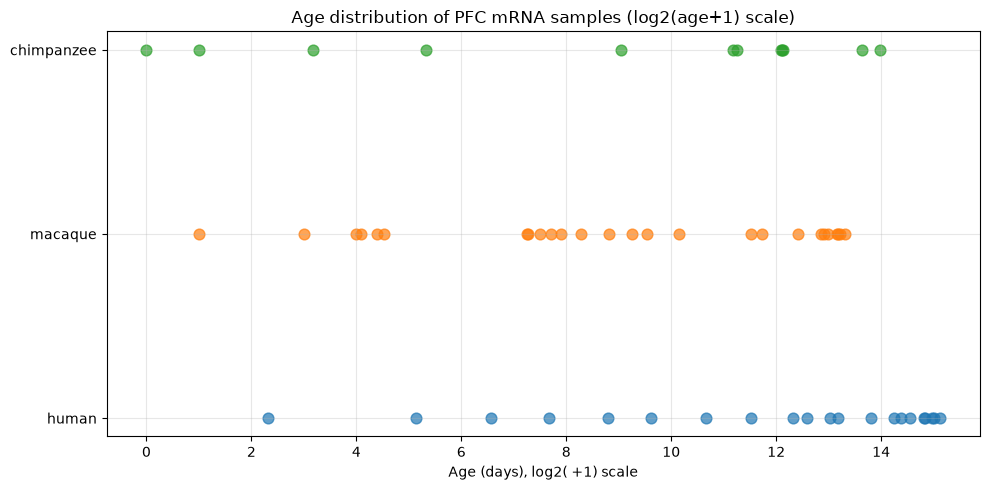

In [89]:
plt.figure(figsize=(10, 5))

for species in sample_info_filt["Species"].unique():
    
    subset = sample_info_filt[
        sample_info_filt["Species"] == species
    ]
    
    plt.scatter(
        subset["Log2_Age"],
        [species] * len(subset),
        label=species,
        s=60,
        alpha=0.7
    )

plt.xlabel("Age (days), log2( +1) scale")
plt.gca().set_yticklabels(
    ["human", "macaque", "chimpanzee"]
)
plt.title("Age distribution of PFC mRNA samples (log2(age+1) scale)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [70]:
pfc_mrna_filt = pfc_mrna_clean.drop(columns=outliers)
pfc_mrna_filt.index = pfc_mrna_filt.index.astype(str)

pfc_mrna_filt.info()


<class 'pandas.DataFrame'>
Index: 13042 entries, 7896822 to 8177222
Data columns (total 59 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   GSM559183  13042 non-null  float64
 1   GSM559184  13042 non-null  float64
 2   GSM559185  13042 non-null  float64
 3   GSM559187  13042 non-null  float64
 4   GSM559188  13042 non-null  float64
 5   GSM559189  13042 non-null  float64
 6   GSM559190  13042 non-null  float64
 7   GSM559191  13042 non-null  float64
 8   GSM559192  13042 non-null  float64
 9   GSM559195  13042 non-null  float64
 10  GSM559196  13042 non-null  float64
 11  GSM559197  13042 non-null  float64
 12  GSM559198  13042 non-null  float64
 13  GSM559200  13042 non-null  float64
 14  GSM559201  13042 non-null  float64
 15  GSM559202  13042 non-null  float64
 16  GSM559203  13042 non-null  float64
 17  GSM559204  13042 non-null  float64
 18  GSM559205  13042 non-null  float64
 19  GSM559206  13042 non-null  float64
 20  GSM559207  130

13.) We now match the identifiers to genes using the annotation from the original data. The annotations are is GPL6244.

In [71]:
# Getting the file using GEOparse, set index to string

gpl = GEOparse.get_GEO(
    geo="GPL6244",
    destdir="data"
)

annotation = gpl.table.copy()
#annotation.index = annotation.index.astype(str)


print(annotation.shape)
display(annotation.head(40))

12-Oct-2026 20:47:57 DEBUG utils - Directory data already exists. Skipping.
12-Oct-2026 20:47:57 INFO GEOparse - File already exist: using local version.
12-Oct-2026 20:47:57 INFO GEOparse - Parsing data/GPL6244.txt: 
12-Oct-2026 20:47:57 DEBUG GEOparse - PLATFORM: GPL6244


(33297, 12)


,ID,GB_LIST,SPOT_ID,seqname,RANGE_GB,RANGE_STRAND,RANGE_START,RANGE_STOP,total_probes,gene_assignment,mrna_assignment,category
0,7896736,NaN,chr1:53049-54936,chr1,NC_000001.10,+,53049,54936,7,---,NONHSAT060105 // NONCODE // Non-coding transcr...,main
1,7896738,NaN,chr1:63015-63887,chr1,NC_000001.10,+,63015,63887,31,ENST00000328113 // OR4G2P // olfactory recepto...,ENST00000328113 // ENSEMBL // havana:known chr...,main
2,7896740,"NM_001004195,NM_001005240,NM_001005484,BC13684...",chr1:69091-70008,chr1,NC_000001.10,+,69091,70008,24,"NM_001004195 // OR4F4 // olfactory receptor, f...",NM_001004195 // RefSeq // Homo sapiens olfacto...,main
3,7896742,"NR_024437,XM_006711854,XM_006726377,XR_430662,...",chr1:334129-334296,chr1,NC_000001.10,+,334129,334296,6,NR_024437 // LOC728323 // uncharacterized LOC7...,NR_024437 // RefSeq // Homo sapiens uncharacte...,main
4,7896744,"NM_001005221,NM_001005224,NM_001005277,NM_0010...",chr1:367659-368597,chr1,NC_000001.10,+,367659,368597,36,"NM_001005221 // OR4F29 // olfactory receptor, ...",NM_001005221 // RefSeq // Homo sapiens olfacto...,main
5,7896746,"AK074482,NC_001807",chr1:564951-565019,chr1,NC_000001.10,+,564951,565019,28,ENST00000387377 // MT-TM // mitochondrially en...,ENST00000387377 // ENSEMBL // mt_genbank_impor...,main
6,7896748,NC_001807,chr1:566062-566129,chr1,NC_000001.10,+,566062,566129,24,ENST00000387382 // MT-TW // mitochondrially en...,ENST00000387382 // ENSEMBL // mt_genbank_impor...,main
7,7896750,NC_001807,chr1:568069-568136,chr1,NC_000001.10,+,568069,568136,28,ENST00000387419 // MT-TD // mitochondrially en...,ENST00000387419 // ENSEMBL // mt_genbank_impor...,main
8,7896752,"M37726,NC_001807",chr1:568844-568913,chr1,NC_000001.10,+,568844,568913,24,ENST00000387421 // MT-TK // mitochondrially en...,ENST00000387421 // ENSEMBL // mt_genbank_impor...,main
9,7896754,"AK026836,AK290103",chr1:721406-721912,chr1,NC_000001.10,+,721406,721912,23,ENST00000540997 // LOC100287497 // uncharacter...,ENST00000540997 // ENSEMBL // havana:known chr...,main


In [72]:
# show columns
print(annotation.columns.tolist())

['ID', 'GB_LIST', 'SPOT_ID', 'seqname', 'RANGE_GB', 'RANGE_STRAND', 'RANGE_START', 'RANGE_STOP', 'total_probes', 'gene_assignment', 'mrna_assignment', 'category']


In [73]:
# show how many expression ids can be found in the annotation

expression_ids = set(pfc_mrna_filt.index)
platform_ids = set(annotation["ID"].astype(str))

print("Expression features:", len(expression_ids))

print(
    "Features found in annotation:",
    len(expression_ids & platform_ids)
)

print(
    "Features not found:",
    len(expression_ids - platform_ids)
)

Expression features: 13042
Features found in annotation: 13042
Features not found: 0


In [74]:
#copy the pfc  annotation into a separate dataframe annotation_pfc

annotation_pfc = annotation.copy()

annotation_pfc["ID"] = annotation_pfc["ID"].astype(str)

annotation_pfc = annotation_pfc.set_index("ID").loc[
    pfc_mrna_filt.index
].copy()

print(annotation_pfc.shape)

(13042, 11)


14.) Extract gene names from column 'gene_assignment. Create function and extract name and number of genes

In [75]:
def extract_genes(assignment):
    if pd.isna(assignment) or assignment.strip() == "---":
        return []

    entries = assignment.split(" /// ")
    genes = set()

    for entry in entries:
        parts = entry.split(" // ")

        if len(parts) >= 2:
            gene = parts[1].strip()

            if gene and gene != "---":
                genes.add(gene)

    return sorted(genes)

In [76]:
#Extract gene names and store in "Gene", number of genes and store in "N_genes" and "Gene", if there is a single gene

annotation_pfc["Genes"] = (
    annotation_pfc["gene_assignment"].apply(extract_genes)
)

annotation_pfc["N_genes"] = (
    annotation_pfc["Genes"].apply(len)
)

annotation_pfc["Gene"] = (
    annotation_pfc["Genes"].apply(
        lambda x: x[0] if len(x) == 1 else None
    )
)

In [77]:
annotation_pfc.sample(5)

,GB_LIST,SPOT_ID,seqname,RANGE_GB,RANGE_STRAND,RANGE_START,RANGE_STOP,total_probes,gene_assignment,mrna_assignment,category,Genes,N_genes,Gene
ID_REF,,,,,,,,,,,,,,
8142554,"NM_005763,AF229180,AK294326,BC144247",chr7:121716187-121784274,chr7,NC_000007.13,-,121716187,121784274,28,NM_005763 // AASS // aminoadipate-semialdehyde...,NM_005763 // RefSeq // Homo sapiens aminoadipa...,main,[AASS],1,AASS
8065992,"NM_001198989,NM_021100,NR_037570,AF097025,AK29...",chr20:34256610-34287281,chr20,NC_000020.10,-,34256610,34287281,41,NM_001198989 // NFS1 // NFS1 cysteine desulfur...,NM_001198989 // RefSeq // Homo sapiens NFS1 cy...,main,[NFS1],1,NFS1
8078252,"NM_152653,XM_005265432,XM_005265433,AK307075,B...",chr3:23244808-23632070,chr3,NC_000003.11,+,23244808,23632070,25,NM_152653 // UBE2E2 // ubiquitin-conjugating e...,NM_152653 // RefSeq // Homo sapiens ubiquitin-...,main,[UBE2E2],1,UBE2E2
7915870,"NM_001042546,NM_001243728,NM_001256418,NM_0227...",chr1:47098409-47134099,chr1,NC_000001.10,-,47098409,47134099,54,NM_001042546 // ATPAF1 // ATP synthase mitocho...,NM_001042546 // RefSeq // Homo sapiens ATP syn...,main,[ATPAF1],1,ATPAF1
8025028,"NM_006012,BC002956",chr19:6361463-6368915,chr19,NC_000019.9,+,6361463,6368915,34,NM_006012 // CLPP // caseinolytic mitochondria...,NM_006012 // RefSeq // Homo sapiens caseinolyt...,main,[CLPP],1,CLPP


15.) We only retain genes, where the number of genes is one, otherwise this would create ambiguity

In [78]:
#save the annotations in unique_features

unique_features = annotation_pfc[
    annotation_pfc["N_genes"] == 1
].copy()

unique_features.head()

,GB_LIST,SPOT_ID,seqname,RANGE_GB,RANGE_STRAND,RANGE_START,RANGE_STOP,total_probes,gene_assignment,mrna_assignment,category,Genes,N_genes,Gene
ID_REF,,,,,,,,,,,,,,
7896822,"NM_198576,XM_006710635,AB191264,AK128761",chr1:955503-991496,chr1,NC_000001.10,+,955503,991496,49,NM_198576 // AGRN // agrin // 1p36.33 // 37579...,NM_198576 // RefSeq // Homo sapiens agrin (AGR...,main,[AGRN],1,AGRN
7897034,"NM_000815,AF016917,AK290861,BC033801",chr1:1950780-1962192,chr1,NC_000001.10,+,1950780,1962192,28,NM_000815 // GABRD // gamma-aminobutyric acid ...,NM_000815 // RefSeq // Homo sapiens gamma-amin...,main,[GABRD],1,GABRD
7897044,"NM_001033581,NM_001033582,NM_001242874,NM_0027...",chr1:1981909-2116834,chr1,NC_000001.10,+,1981909,2116834,48,"NM_001033581 // PRKCZ // protein kinase C, zet...",NM_001033581 // RefSeq // Homo sapiens protein...,main,[PRKCZ],1,PRKCZ
7897068,"NM_003036,XM_005244776",chr1:2160134-2241558,chr1,NC_000001.10,+,2160134,2241558,44,NM_003036 // SKI // SKI proto-oncogene // 1p36...,NM_003036 // RefSeq // Homo sapiens v-ski avia...,main,[SKI],1,SKI
7897078,"NM_007033,XM_006710305,XM_006710306,AF091071,A...",chr1:2323214-2336874,chr1,NC_000001.10,+,2323214,2336874,36,NM_007033 // RER1 // retention in endoplasmic ...,NM_007033 // RefSeq // Homo sapiens retention ...,main,[RER1],1,RER1


In [79]:
# Find the genes represented by multiple features

gene_counts = unique_features["Gene"].value_counts()

print("Genes total:", len(set(unique_features["Gene"])))
print("Genes represented by multiple features:",
      (gene_counts > 1).sum())

Genes total: 11783
Genes represented by multiple features: 116


16.) We decide to retain only the genes that have single feature

In [80]:
# Select genes represented by exactly one feature
single_genes = gene_counts[gene_counts == 1].index

# Keep their annotations
single_features = unique_features[
    unique_features["Gene"].isin(single_genes)
].copy()

print("Genes retained:", len(single_features))

Genes retained: 11667


In [81]:
# Select the retained features
mrna_gene = pfc_mrna_filt.loc[single_features.index].copy()

# Replace feature identifiers with gene symbols
mrna_gene.index = single_features["Gene"].values
mrna_gene.index.name = "Gene"

print(mrna_gene.shape)

(11667, 59)


17.) Export gene-expression matrix and mapping/annotation data

In [ ]:
mrna_gene.to_csv("data/pfc_mrna_gene_expression.csv")
single_features.to_csv("data/pfc_mrna_gene_annotation.csv")

18.) Exploratory data analyis / Correlation between species, age and  age and species

In [ ]:
#Transpose matrix
Y = mrna_gene.T

print(Y.shape)


(59, 11667)


In [ ]:
#align metadata
info = sample_info_filt.set_index("GSM").loc[Y.index]

In [ ]:
# get dummy veriables
age = np.log2(info["Age_days"].astype(float) + 1)

species = pd.get_dummies(
    info["Species"],
    drop_first=True,
    dtype=float
)

In [ ]:
# create design matrices
X_species = species

X_age = age.to_frame(name="Log2_Age")

X_both = pd.concat([species, X_age], axis=1)

In [ ]:
# use linear regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [ ]:
# fit species model
model_species = LinearRegression()
model_species.fit(X_species, Y)

Y_pred_species = model_species.predict(X_species)

#Calculate R^2 value for every gene
r2_species = r2_score(
    Y,
    Y_pred_species,
    multioutput="raw_values"
)

In [ ]:
#fit age model

model_age = LinearRegression()
model_age.fit(X_age, Y)

r2_age = r2_score(
    Y,
    model_age.predict(X_age),
    multioutput="raw_values"
)

In [ ]:
#fit both age and species

model_both = LinearRegression()
model_both.fit(X_both, Y)

r2_both = r2_score(
    Y,
    model_both.predict(X_both),
    multioutput="raw_values"
)


In [ ]:
# create regression results table

regression_results = pd.DataFrame({
    "Gene": Y.columns,
    "R2_species": r2_species,
    "R2_age": r2_age,
    "R2_both": r2_both
}).set_index("Gene")

In [ ]:
# additional contribution of age and species

regression_results["Age_given_species"] = (
    regression_results["R2_both"]
    - regression_results["R2_species"]
)

regression_results["Species_given_age"] = (
    regression_results["R2_both"]
    - regression_results["R2_age"]
)

In [ ]:
# summmarize results

display(regression_results.describe())

,R2_species,R2_age,R2_both,Age_given_species,Species_given_age
count,11667.000000,1.166700e+04,11667.000000,1.166700e+04,11667.000000
mean,0.255795,1.347159e-01,0.383497,1.277027e-01,0.248782
std,0.216198,1.679708e-01,0.225188,1.671443e-01,0.209105
min,0.000003,3.322900e-08,0.001226,2.103260e-10,0.000001
25%,0.078174,1.365311e-02,0.191710,1.076525e-02,0.077295
50%,0.191588,6.422645e-02,0.365964,5.539057e-02,0.187486
75%,0.388546,1.930086e-01,0.555844,1.788426e-01,0.374100
max,0.976665,8.804142e-01,0.977214,8.747477e-01,0.958419
